# Exercise 5: Sinusoidal model

This exercise explores sinusoidal analysis and tracking using the sinusoidal model from `smstools`. It has four parts:
1. Minimise the frequency estimation error of a sinusoid
2. Track a two-component linear chirp
3. Track sinusoids of very different amplitudes
4. Sinusoidal modelling of a multicomponent signal

### Relevant concepts

**Chirp signals:** A chirp is a signal whose instantaneous frequency changes over time. A *linear* chirp sweeps frequency at a constant rate. Analysing a chirp with the STFT involves a fundamental tradeoff: resolving two closely spaced frequency components requires a *long* window (narrow main lobe), but tracking a rapidly changing frequency requires a *short* window (good time localisation). The optimal window size balances these competing demands.

**Sinusoidal modelling and sine tracking:** The sinusoidal model represents each audio frame as a sum of sinusoids. The `sineModelAnal()` function detects spectral peaks in each frame and links them across frames into *tracks*. The key parameters are:

- `maxnSines`: maximum number of sinusoidal tracks per frame
- `minSineDur`: minimum track duration in seconds (shorter tracks are discarded as spurious)
- `freqDevOffset`: minimum allowed frequency deviation at 0 Hz (sets the tracking tolerance)
- `freqDevSlope`: how much the deviation tolerance grows with frequency (compensates for the tendency of higher-frequency tracks to vary more)

Setting `minSineDur = 0` retains all detected peaks with no duration filtering.

**Tracking low-amplitude sinusoids:** When two sinusoids have very different amplitudes, the *sidelobes* of the stronger component can mask the main lobe of the weaker one. The choice of analysis window is critical: windows with high sidelobe levels (e.g. rectangular) will bury weak components, while windows with strong sidelobe attenuation (e.g. Blackman-Harris) keep sidelobes well below the weak component's main lobe.


## Part 1 – Minimising the frequency estimation error of a sinusoid

The function `min_freq_est_err()` should find the smallest valid window size `M` such that the frequency estimation error is less than 0.05 Hz, and return the estimated frequency along with the parameters used.

**Analysis setup:**
- Window type: Blackman
- Analysis frame: centred at $t = 0.5$ s
- Peak detection threshold: $t = -40$ dB
- Use `dftAnal()`, `peakDetection()`, and `peakInterp()` from `dftModel.py`

**Finding M:** Iterate over candidate window sizes of the form $M = 100k + 1$ for $k = 1, 2, 3, \ldots$ and stop at the first value for which $|f - f_{\mathrm{est}}| < 0.05$ Hz. For each `M`, set the FFT size `N` to the smallest power of 2 larger than `M`.

**Inputs:**
- `input_file` (str): path to a `.wav` file containing a single stationary sinusoid (length ≥ 1 s)
- `f` (float): true frequency of the sinusoid in Hz (range: 100–2000 Hz)

**Output:** tuple `(f_est, M, N)` — estimated frequency in Hz, window size, and FFT size.


In [1]:
import numpy as np
from scipy.signal import get_window
import math
from smstools.models import dftModel as DFT
from smstools.models import utilFunctions as UF
from smstools.models import stft
from smstools.models import sineModel as SM
import IPython.display as ipd

In [2]:
# E5 - 1.1: Complete the function min_freq_est_err()

def min_freq_est_err(input_file, f):
        """Best estimate the frequency of a sinusoid by iterating over different sizes of analysis window.

        Args:
                input_file (str): wav file
                f (float): frequency of the sinusoid present in the input audio signal (Hz)

        Result:
                f_est (float): estimated frequency of the sinusoid (Hz)
                M (int): Window size
                N (int): FFT size

        """
        # analysis parameters:
        window = 'blackman'
        t = -40

        # M = 100*k + 1 for k = 1,2, ...k 
        # fest - f < |0.05| Hz 
        # peakdetection function 

        fs, x = UF.wavread(input_file)
        for k in np.range(100):
                M = 100*k + 1
                N = int(pow(2, np.ceil(np.log2(M))))

                w = get_window('blackman', M)
                n = np.arange(M)
                mX, pX = DFT.dftAnal(x, w, N)

                ploc = UF.peakDetection(mX, t)
                iploc, ipmag, ipphase = UF.peakInterp(mX, pX, ploc)
                peak_freqs = ploc * fs / float(N)
                interp_freqs = iploc * fs / float(N)
                if np.abs(interp_freqs[0] - f) < 0.05: 
                        return interp_freqs[0], M, N 
                        

In [3]:
# E5 - 1.1: Complete the function min_freq_est_err()

def min_freq_est_err(input_file, f, zp=1):
        """Best estimate the frequency of a sinusoid by iterating over different sizes of analysis window.

        Args:
                input_file (str): wav file
                f (float): frequency of the sinusoid present in the input audio signal (Hz)
                zp (int): zero-padding factor, N is the smallest power of 2 >= zp*M (zp = 1: no extra padding)

        Result:
                f_est (float): estimated frequency of the sinusoid (Hz)
                M (int): Window size
                N (int): FFT size

        """
        # analysis parameters:
        window = 'blackman'
        t = -40

        # M = 100*k + 1 for k = 1,2, ...k 
        # fest - f < |0.05| Hz 
        # peakdetection function 
        fs, x = UF.wavread(input_file)
        center = int(0.5 * fs)

        for k in range(1, 100):
            M = 100 * k + 1
            N = int(pow(2, np.ceil(np.log2(zp * M))))
            w = get_window(window, M)

            hM1 = (M + 1) // 2
            hM2 = M // 2
            x1 = x[center - hM1 : center + hM2]

            mX, pX = DFT.dftAnal(x1, w, N)
            ploc = UF.peakDetection(mX, t)
            iploc, ipmag, ipphase = UF.peakInterp(mX, pX, ploc)
            interp_freqs = iploc * fs / float(N)

            if ploc.size > 0 and np.abs(interp_freqs[0] - f) < 0.05:
                return interp_freqs[0], M, N


Test cases for `min_freq_est_err()`:

**Test case 1:** `sine-490.wav`, `f = 490.0 Hz` → `M = 1101`, `N = 2048`, `f_est ≈ 489.963 Hz`, error ≈ 0.037 Hz

**Test case 2:** `sine-1000.wav`, `f = 1000.0 Hz` → `M = 1101`, `N = 2048`, `f_est ≈ 1000.02 Hz`, error ≈ 0.020 Hz

**Test case 3:** `sine-200.wav`, `f = 200.0 Hz` → `M = 1201`, `N = 2048`, `f_est ≈ 200.038 Hz`, error ≈ 0.038 Hz

For each test case, generate a new sinusoid at `f_est` and listen to it alongside the original to check whether the estimation error is perceptually audible.


In [4]:
# E5 - 1.2: For each test case, call min_freq_est_err(), generate and play both the original and the
#            estimated sinusoid, and compare them perceptually.

test_cases = [('../sounds/sine-490.wav', 490.0),
              ('../sounds/sine-1000.wav', 1000.0),
              ('../sounds/sine-200.wav', 200.0)]

for input_file, f in test_cases:
    fs, x = UF.wavread(input_file)
    f_est, M, N = min_freq_est_err(input_file, f)

    # sinusoid at the estimated frequency, same length and amplitude as the original
    n = np.arange(x.size)
    y = np.max(np.abs(x)) * np.cos(2 * np.pi * f_est * n / fs)

    print(f'{input_file}: f = {f} Hz, f_est = {f_est:.3f} Hz, error = {abs(f - f_est):.3f} Hz, M = {M}, N = {N}')
    print('original:')
    ipd.display(ipd.Audio(data=x, rate=fs))
    print('estimated:')
    ipd.display(ipd.Audio(data=y, rate=fs))


../sounds/sine-490.wav: f = 490.0 Hz, f_est = 489.963 Hz, error = 0.037 Hz, M = 1101, N = 2048
original:


estimated:


../sounds/sine-1000.wav: f = 1000.0 Hz, f_est = 1000.020 Hz, error = 0.020 Hz, M = 1101, N = 2048
original:


estimated:


../sounds/sine-200.wav: f = 200.0 Hz, f_est = 200.038 Hz, error = 0.038 Hz, M = 1201, N = 2048
original:


estimated:


**E5 - 1.3: Conceptual questions (answer here)**

1. Why does a larger window size generally reduce the frequency estimation error? What property of the DFT is responsible? Verify by running `min_freq_est_err` on one test case and printing the error at each candidate `M`.
2. For the test cases above, the optimal `M` is around 1100–1200 samples. Does the required `M` depend on the frequency `f`? Try `f = 300 Hz` and `f = 1500 Hz` and compare the optimal `M` values. Explain the trend (or lack of one).
3. Can you hear a difference between the original and estimated sinusoids for any of the three test cases? What does this tell you about the perceptual relevance of a 0.05 Hz estimation error?


**Respuestas E5 - 1.3**

**1.** Una ventana más larga tiene un lóbulo principal más estrecho (`6·fs/M` Hz en la Blackman), así que el pico queda mejor definido y se solapa menos con su imagen en `-f`. La propiedad responsable es la relación inversa entre la duración de la ventana y el ancho de su espectro.

La tabla de errores con `sine-490.wav` muestra esa tendencia general: 62.8 Hz con `M = 101`, 0.335 Hz con `M = 201` y 0.037 Hz con `M = 1101`. La bajada no es continua, porque el error también depende de `N/M`. Con `N` fijo, al subir `M` el lóbulo cubre menos bins y la interpolación parabólica empeora (por ejemplo, de 0.037 Hz con `M = 1101` a 0.071 Hz con `M = 1501`). Con zero-padding (`zp = 8`) esos saltos casi desaparecen y el error baja hasta unos 0.0001 Hz.

**2.** Sí depende de `f`, pero sin una tendencia simple cuando `N` es la potencia de 2 del enunciado: `M = 401` para 300 Hz y `M = 1101` para 1500 Hz, pero `M = 601` para 2000 Hz. En esos casos pesa mucho el error de interpolación, que depende de dónde cae `f` entre dos bins.

Al eliminar ese error con un `N` muy grande, la tendencia es que `M` baja al subir `f`: 1001 para 100 Hz, 601 para 200 Hz, 401 para 300 Hz y unos 200-300 entre 490 y 2000 Hz. La separación entre bins y el ancho del lóbulo en Hz son iguales para cualquier `f`, así que una `f` alta no exige más `M`. Las frecuencias bajas sí lo exigen, porque su lóbulo se solapa con la imagen en `-f`. Para separarlos hace falta aproximadamente `M > 3·fs/f`.

**3.** *(Pendiente de confirmar escuchando.)* No debería oírse diferencia. Los errores son de 0.037 Hz, 0.020 Hz y 0.038 Hz, es decir, unos 0.13, 0.03 y 0.33 cents, muy por debajo de lo que se suele distinguir (unos pocos cents). Además, si sonaran a la vez, el batido entre ellas tardaría más de 25 s en completarse, mucho más que la duración de los sonidos (1-2 s). Por tanto, un error de 0.05 Hz es perceptualmente irrelevante en este rango de frecuencias.


In [5]:
# E5 - 1.3: Error at each candidate M for a single input signal

input_file = '../sounds/sine-490.wav'
f = 490.0

window = 'blackman'
t = -40
fs, x = UF.wavread(input_file)
center = int(0.5 * fs)
zp = 1      # zero-padding factor: N is the smallest power of 2 >= zp*M (zp = 1: no extra padding)

print('    M      N       f_est     error')
for k in range(1, 16):
    M = 100 * k + 1
    N = int(pow(2, np.ceil(np.log2(zp * M))))
    w = get_window(window, M)

    hM1 = (M + 1) // 2
    hM2 = M // 2
    x1 = x[center - hM1 : center + hM2]

    mX, pX = DFT.dftAnal(x1, w, N)
    ploc = UF.peakDetection(mX, t)
    iploc, ipmag, ipphase = UF.peakInterp(mX, pX, ploc)
    interp_freqs = iploc * fs / float(N)

    if ploc.size > 0:
        print(f'{M:5d}  {N:5d}  {interp_freqs[0]:10.3f}  {abs(interp_freqs[0] - f):8.3f}')
    else:
        print(f'{M:5d}  {N:5d}  no peak found')


    M      N       f_est     error
  101    128     552.759    62.759
  201    256     489.665     0.335
  301    512     489.742     0.258
  401    512     489.633     0.367
  501    512     489.448     0.552
  601   1024     490.074     0.074
  701   1024     490.108     0.108
  801   1024     490.144     0.144
  901   1024     490.183     0.183
 1001   1024     490.230     0.230
 1101   2048     489.963     0.037
 1201   2048     489.955     0.045
 1301   2048     489.947     0.053
 1401   2048     489.939     0.061
 1501   2048     489.929     0.071


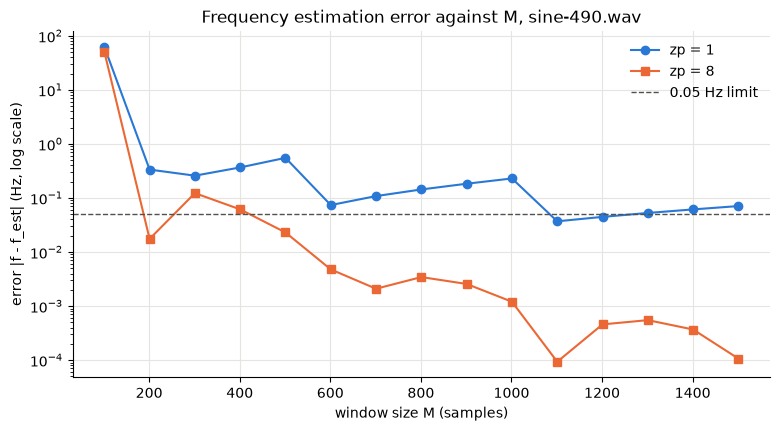

In [6]:
# E5 - 1.3: Plot of the estimation error against M, with and without zero padding
# (uses input_file, f, x, fs, center, window and t from the cell above)

import matplotlib.pyplot as plt

Ms = [100 * k + 1 for k in range(1, 16)]
series = [(1, '#2a78d6', 'o'), (8, '#eb6834', 's')]      # (zp, color, marker)

fig, ax = plt.subplots(figsize=(9, 4.5))
for zp_plot, color, marker in series:
    errors = []
    for M in Ms:
        N = int(pow(2, np.ceil(np.log2(zp_plot * M))))
        w = get_window(window, M)
        hM1 = (M + 1) // 2
        hM2 = M // 2
        mX, pX = DFT.dftAnal(x[center - hM1 : center + hM2], w, N)
        ploc = UF.peakDetection(mX, t)
        iploc, ipmag, ipphase = UF.peakInterp(mX, pX, ploc)
        errors.append(abs(iploc[0] * fs / float(N) - f))
    ax.plot(Ms, errors, color=color, marker=marker, markersize=6, linewidth=1.5, label=f'zp = {zp_plot}')

ax.axhline(0.05, color='#52514e', linestyle='--', linewidth=1, label='0.05 Hz limit')
ax.set_yscale('log')
ax.set_xlabel('window size M (samples)')
ax.set_ylabel('error |f - f_est| (Hz, log scale)')
ax.set_title(f'Frequency estimation error against M, {input_file.split("/")[-1]}')
ax.grid(True, which='major', color='#e5e4e0', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()


In [7]:
# E5 - 1.3 (question 2): Does the required M depend on the frequency f?

import os, tempfile

fs = 44100
n = np.arange(fs)                                      # 1 second of signal
freqs = [200.0, 300.0, 490.0, 1000.0, 1500.0, 2000.0]

print('     f      M      N       f_est    error  true bin')
with tempfile.TemporaryDirectory() as tmp:
    for f in freqs:
        path = os.path.join(tmp, f'sine-{int(f)}.wav')
        UF.wavwrite(0.8 * np.sin(2 * np.pi * f * n / fs), fs, path)

        f_est, M, N = min_freq_est_err(path, f, zp=1)  # zp=1: N as defined in the statement
        print(f'{f:6.0f}  {M:5d}  {N:5d}  {f_est:10.3f}  {abs(f - f_est):7.3f}  {f * N / fs:8.2f}')


     f      M      N       f_est    error  true bin
   200   1201   2048     200.038    0.038      9.29
   300    401    512     300.045    0.045      3.48
   490   1101   2048     489.963    0.037     22.76
  1000   1101   2048    1000.020    0.020     46.44
  1500   1101   2048    1499.964    0.036     69.66
  2000    601   1024    2000.048    0.048     46.44


## Part 2 – Tracking a two-component linear chirp

Use `freq_tracker_error()` to find the window size `M` that best tracks both frequency components of `chirp-150-190-linear.wav`, aiming for a mean estimation error below 2 Hz on each component.

The file contains a two-component linear chirp: one sinusoid sweeping from 150 Hz to 1400 Hz and another from 190 Hz to 1440 Hz, both over 2 seconds. The two components are only 40 Hz apart throughout, so resolving them requires a large window — but a very large window will smear the rapidly changing frequencies. Finding the right balance is the core challenge.

**Fixed parameters:** `window = 'blackman'`, `t = -80`, `H = 128`.

**Your task:** Choose `M` analytically (think about the frequency separation and the required main-lobe width), then verify with `freq_tracker_error()`. Plot the true vs. estimated frequency tracks for both your initial choice (`M = 1023` as a baseline) and your improved value.

> Tip: use `gen_time_stamps()` to generate the time axis and `gen_true_freq_tracks_chirp_150_190()` to get the reference tracks for comparison.


In [5]:
# functions used in exercises of Part 2 and 3

def gen_time_stamps(xlen, M, fs, H):
    """Generate frame time stamps for a given signal length and sampling rate.

    Args:
        xlen (int): duration of signal in samples
        M (int): window size
        fs (int): sampling rate
        H (int): hop size

    Result:
        np.array: time stamps

    """
    hM1 = int(np.floor((M+1)/2))
    hM2 = int(np.floor(M/2))
    xlen = xlen + 2*hM2
    pin = hM1
    pend = xlen - hM1
    tStamps = np.arange(pin,pend,H)/float(fs)
    return tStamps

def gen_true_freq_tracks_chirp_150_190(tStamps):
    """Generate the frequency values present in file "../sounds/chirp-150-190-linear.wav"

    Args:
        tStamps (np.array): time stamps

    Result:
        np.array: time stamps and frequency values of predefined chirp

    """
    fTrack = np.zeros((len(tStamps),2))
    fTrack[:,0] = np.transpose(np.linspace(190, 190+1250, len(tStamps)))
    fTrack[:,1] = np.transpose(np.linspace(150, 150+1250, len(tStamps)))
    return fTrack

def gen_true_freq_tracks_440_602(tStamps):
    """Generate the frequency values present in file "../sounds/sines-440-602-hRange.wav"

    Args:
        tStamps (np.array): time stamps

    Result:
        np.array: time stamps and frequency values of predefined chirp

    """
    fTrack = np.zeros((len(tStamps),2))
    fTrack[:,0] = np.transpose(440*np.ones((len(tStamps),1)))
    fTrack[:,1] = np.transpose(602*np.ones((len(tStamps),1)))
    return fTrack

def freq_tracker_error(input_file, fTrackTrue, window, t, H, M):
    """Estimate sinusoidal values of a sound

    Args:
        input_file (str): wav file including the path
        fTrackTrue (np.array): array of true frequency values, one row per time frame, one column per component
        window (str): window type used for analysis
        t (float): peak picking threshold (negative dB)
        H (int): hop size in samples
        M (int): window size in samples

   Result:
           float: mean estimation error
           np.array: estimated frequency values, one row per time frame, one column per component

    """

    N = int(pow(2, np.ceil(np.log2(M))))        # FFT Size, power of 2 larger than M
    maxnSines = 2                               # Maximum number of sinusoids at any time frame
    minSineDur = 0.0                            # minimum duration set to zero to not do tracking
    freqDevOffset = 30                          # minimum frequency deviation at 0Hz
    freqDevSlope = 0.001                        # slope increase of minimum frequency deviation

    fs, x = UF.wavread(input_file)              # read input sound
    w = get_window(window, M)                   # Compute analysis window
    # analyze the sound with the sinusoidal model
    fTrackEst, mTrackEst, pTrackEst = SM.sineModelAnal(x, fs, w, N, H, t, maxnSines, minSineDur, freqDevOffset, freqDevSlope)
    tailF = 20
    # Compute mean estimation error. 20 frames at the beginning and end not used to compute error
    meanErr = np.mean(np.abs(fTrackTrue[tailF:-tailF,:] - fTrackEst[tailF:-tailF,:]),axis=0)

    return (meanErr, fTrackEst)

**Baseline test case:** `M = 1023` gives mean errors of `[13.7, 528.5]` Hz — far above the 2 Hz target. The second component is almost completely untracked.

Start by reasoning about **why** `M = 1023` fails: what is the main-lobe width in Hz for that window size at the sampling rate of the file? Is it narrow enough to resolve components 40 Hz apart? Then calculate the minimum `M` theoretically, test it, and refine.


In [3]:
# E5 - 2.1: Call freq_tracker_error() with the baseline M=1023 and plot true vs estimated tracks.
#            Then find and apply an improved M, and plot the new estimated tracks.

import matplotlib.pyplot as plt

H = 128
window = 'blackman'
t = -80
input_file = '../sounds/chirp-150-190-linear.wav'
fs, x = UF.wavread(input_file)

# baseline test
M = 1023
tStamps = gen_time_stamps(x.size, M, fs, H)
fTrackTrue = gen_true_freq_tracks_chirp_150_190(tStamps)

### Your code here
freq_tracker_error(input_file, fTrackTrue, window, t, H, M)

(array([ 13.66932655, 559.49786224]),
 array([[ 177.94333949,    0.        ],
        [ 180.17316851,    0.        ],
        [ 188.13123744,    0.        ],
        ...,
        [1429.49854009,    0.        ],
        [1423.3154946 ,    0.        ],
        [1421.79351832,    0.        ]]))

In [4]:

Bs = 6
sep = Bs * fs / M 
print(sep)

258.65102639296185


In [5]:
# 344 >> 40 Hz 
min_M = (Bs * fs) / 40
print(min_M)

6615.0


In [6]:
import matplotlib.pyplot as plt

H = 128
window = 'blackman'
t = -80
input_file = '../sounds/chirp-150-190-linear.wav'
fs, x = UF.wavread(input_file)

# baseline test
M = int(min_M)
tStamps = gen_time_stamps(x.size, M, fs, H)
fTrackTrue = gen_true_freq_tracks_chirp_150_190(tStamps)

### Your code here
freq_tracker_error(input_file, fTrackTrue, window, t, H, M)

(array([197.4604435 , 221.22366867]),
 array([[ 209.71443742,  174.16683528],
        [ 210.16350623,  174.80023031],
        [ 210.6131669 ,  175.30545944],
        ...,
        [1298.483357  , 1287.14551348],
        [1309.30508247, 1297.47505793],
        [1308.09657748, 1294.57530962]]))

    M    error 190-1440 Hz    error 150-1400 Hz


 1023              13.67               559.50


 2047               7.02               457.75


 3001               1.28                33.39


 3501               0.86                 1.67


 4095               0.72                 1.30


 4501               0.74                 1.33


 5001               0.94               170.02


 6001             207.18               367.30


 6615             197.46               221.22


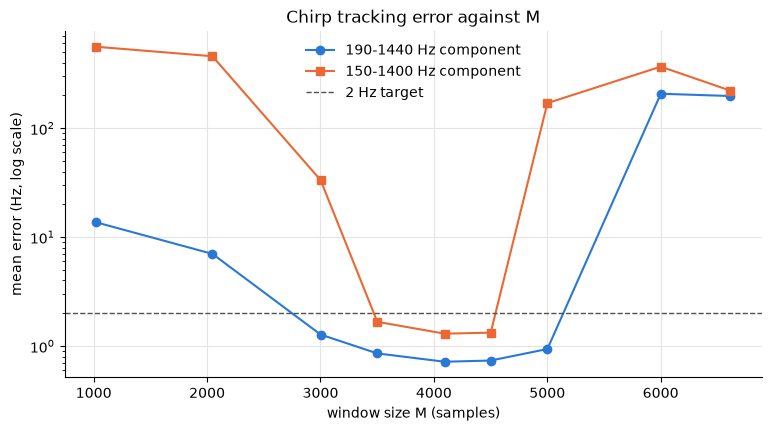

In [7]:
# E5 - 2.1: Mean estimation error of each component for several window sizes
# (uses input_file, x, fs, window, t and H from the cells above)

Ms = [1023, 2047, 3001, 3501, 4095, 4501, 5001, 6001, 6615]
errors = []

print('    M    error 190-1440 Hz    error 150-1400 Hz')
for M_test in Ms:
    tStamps = gen_time_stamps(x.size, M_test, fs, H)
    fTrackTrue = gen_true_freq_tracks_chirp_150_190(tStamps)
    meanErr, fTrackEst = freq_tracker_error(input_file, fTrackTrue, window, t, H, M_test)
    errors.append(meanErr)
    print(f'{M_test:5d}  {meanErr[0]:17.2f}  {meanErr[1]:19.2f}')
errors = np.array(errors)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(Ms, errors[:, 0], color='#2a78d6', marker='o', markersize=6, linewidth=1.5, label='190-1440 Hz component')
ax.plot(Ms, errors[:, 1], color='#eb6834', marker='s', markersize=6, linewidth=1.5, label='150-1400 Hz component')
ax.axhline(2, color='#52514e', linestyle='--', linewidth=1, label='2 Hz target')
ax.set_yscale('log')
ax.set_xlabel('window size M (samples)')
ax.set_ylabel('mean error (Hz, log scale)')
ax.set_title('Chirp tracking error against M')
ax.grid(True, which='major', color='#e5e4e0', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()


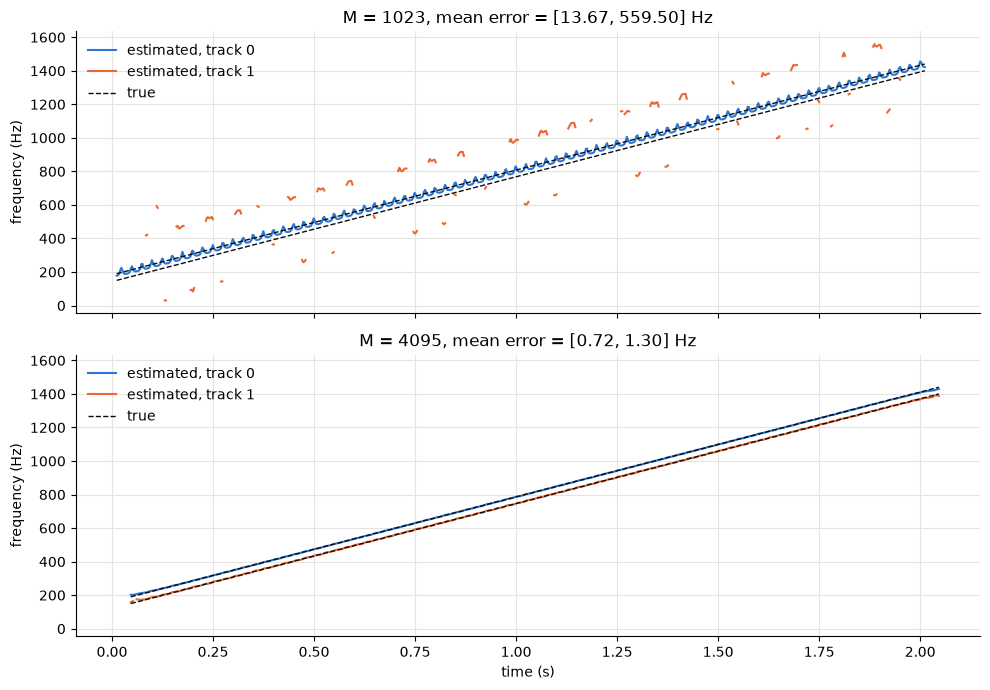

In [8]:
# E5 - 2.1: True against estimated frequency tracks over time, baseline and improved M
# (uses input_file, x, fs, window, t and H from the cells above)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)

for ax, M_test in zip(axes, [1023, 4095]):
    tStamps = gen_time_stamps(x.size, M_test, fs, H)
    fTrackTrue = gen_true_freq_tracks_chirp_150_190(tStamps)
    meanErr, fTrackEst = freq_tracker_error(input_file, fTrackTrue, window, t, H, M_test)
    fTrackEst = np.where(fTrackEst > 0, fTrackEst, np.nan)      # 0 means no track in that frame

    ax.plot(tStamps, fTrackEst[:, 0], color='#2a78d6', linewidth=1.5, label='estimated, track 0')
    ax.plot(tStamps, fTrackEst[:, 1], color='#eb6834', linewidth=1.5, label='estimated, track 1')
    ax.plot(tStamps, fTrackTrue, color='#0b0b0b', linestyle='--', linewidth=1)
    ax.plot([], [], color='#0b0b0b', linestyle='--', linewidth=1, label='true')

    ax.set_title(f'M = {M_test}, mean error = [{meanErr[0]:.2f}, {meanErr[1]:.2f}] Hz')
    ax.set_ylabel('frequency (Hz)')
    ax.grid(True, color='#e5e4e0', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, loc='upper left')

axes[1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()


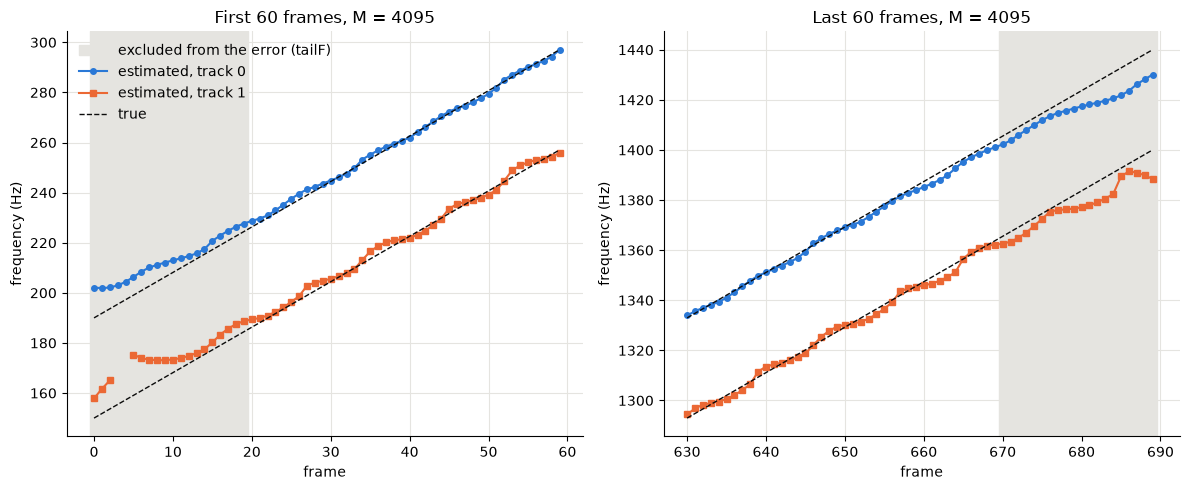

frames affected by the padding: 15
mean error (Hz)        track 0   track 1
excluded start            5.70      6.80
central frames            0.72      1.30
excluded end              6.43      5.19


In [10]:
# E5 - 2.3 (question 3): Frequency tracks at the start and end of the sound
# (uses input_file, x, fs, window, t and H from the cells above)

M_test = 4095       # window size to inspect
n_frames = 60       # number of frames to show at each end
tailF = 20          # frames left out of the error by freq_tracker_error()

tStamps = gen_time_stamps(x.size, M_test, fs, H)
fTrackTrue = gen_true_freq_tracks_chirp_150_190(tStamps)
meanErr, fTrackEst = freq_tracker_error(input_file, fTrackTrue, window, t, H, M_test)
fTrackEst = np.where(fTrackEst > 0, fTrackEst, np.nan)      # 0 means no track in that frame
last = tStamps.size

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
regions = [('First', np.arange(n_frames), (-0.5, tailF - 0.5)),
           ('Last', np.arange(last - n_frames, last), (last - tailF - 0.5, last - 0.5))]

for ax, (name, frames, excluded) in zip(axes, regions):
    ax.axvspan(*excluded, color='#e5e4e0', label='excluded from the error (tailF)')
    ax.plot(frames, fTrackEst[frames, 0], color='#2a78d6', marker='o', markersize=4, linewidth=1.5, label='estimated, track 0')
    ax.plot(frames, fTrackEst[frames, 1], color='#eb6834', marker='s', markersize=4, linewidth=1.5, label='estimated, track 1')
    ax.plot(frames, fTrackTrue[frames], color='#0b0b0b', linestyle='--', linewidth=1)
    ax.plot([], [], color='#0b0b0b', linestyle='--', linewidth=1, label='true')
    ax.set_xlabel('frame')
    ax.set_ylabel('frequency (Hz)')
    ax.set_title(f'{name} {n_frames} frames, M = {M_test}')
    ax.grid(True, color='#e5e4e0', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

error = np.abs(fTrackTrue - fTrackEst)
print(f'frames affected by the padding: {M_test // 2 // H}')
print('mean error (Hz)        track 0   track 1')
print(f'excluded start         {np.nanmean(error[:tailF, 0]):7.2f}   {np.nanmean(error[:tailF, 1]):7.2f}')
print(f'central frames         {np.nanmean(error[tailF:-tailF, 0]):7.2f}   {np.nanmean(error[tailF:-tailF, 1]):7.2f}')
print(f'excluded end           {np.nanmean(error[-tailF:, 0]):7.2f}   {np.nanmean(error[-tailF:, 1]):7.2f}')


**E5 - 2.3: Conceptual questions (answer here)**

1. What is the Blackman window's main-lobe width (in Hz) for `M = 1023` at the sampling rate of the chirp file? Is it narrow enough to resolve two components 40 Hz apart? Repeat the calculation for your improved `M`.
2. Increasing `M` improves frequency resolution but degrades time resolution. From your plot of the estimated frequency tracks, do you observe any blurring or smearing of the chirp trajectory for large `M`? At what window size does this become visible?
3. The first and last 20 frames (`tailF = 20`) are excluded from the error calculation. Why? What happens to the frequency tracks in those boundary regions?


**Respuestas E5 - 2.3**

**1.** Con la Blackman, `fs = 44100` y `M = 1023`, el lóbulo mide `6·fs/M ≈ 259 Hz`, mucho más que los 40 Hz de separación, así que las dos componentes se funden en un solo pico. Con `M = 4095` mide unos 65 Hz. Sigue siendo mayor que 40 Hz, pero ya separa las dos pistas, con un error de `[0.72, 1.30]` Hz. La condición `6·fs/M ≤ 40` da `M ≥ 6615`, pero es más estricta de lo necesario y no tiene en cuenta que la frecuencia se mueve.

**2.** Sí. El chirp sube 625 Hz/s, así que dentro de la ventana la frecuencia recorre unos `625·M/fs` Hz: 58 Hz con `M = 4095` y 94 Hz con `M = 6615`. El efecto empieza a notarse en `M = 5001`, donde la pista de 150-1400 Hz falla (error de 170 Hz). Con `M = 6001` fallan las dos (207 y 367 Hz). El rango válido entre los valores probados es `M` de 3501 a 4501.

**3.** En esos frames la ventana se solapa con los ceros de relleno, así que solo ve una parte de la señal y la estimación se desvía hacia el interior del sonido: por encima de la frecuencia real al inicio y por debajo al final. Con `M = 4095` el error en esas zonas es de unos 5-7 Hz, frente a 0.72 y 1.30 Hz en los frames centrales. Por eso se excluyen: no reflejan la calidad del análisis, sino el efecto de los bordes.


## Part 3 – Tracking sinusoids of different amplitudes

Use `freq_tracker_error()` to find the window type `window` and magnitude threshold `t` that best track both sinusoids in `sines-440-602-hRange.wav`, aiming for a mean estimation error below 2 Hz on each component.

The signal is $s = \sin(2\pi \cdot 440 \cdot t) + 2\times10^{-3}\sin(2\pi \cdot 602 \cdot t)$: one component at 440 Hz and a second at 602 Hz that is **1000 times weaker** (−60 dB). The weak component's main lobe must be detectable above the sidelobes of the dominant component.

**Fixed parameters:** `M = 2047`, `N = 4096`, `H = 128`, `minSineDur = 0.02`, `freqDevOffset = 10`, `freqDevSlope = 0.001`, `maxnSines = 2`.

**Your task:** Choose `window` based on its sidelobe attenuation (compare `'boxcar'`, `'hanning'`, `'hamming'`, `'blackman'`, `'blackmanharris'`), and set `t` (in dB, negative) to capture the weak component without picking up noise. Plot the true vs. estimated tracks for the baseline (`window='hanning'`, `t=-80`) and your improved parameters.

**Baseline test case:** `window = 'hanning'`, `t = -80` → mean errors `[0.196, 29.5]` Hz. The weak 602 Hz component is tracked poorly.


mean error of the 602 Hz component (Hz)
        window  t =  -60  t =  -70  t =  -80  t = -100  t = -120
        boxcar   602.000   602.000  6146.663  7984.083  7984.083
          hann   197.533    29.511    29.511    29.511    29.511
       hamming   261.312   261.312   261.312   261.312   261.312
      blackman   362.612     2.382     2.382     2.382     2.382
blackmanharris   602.000     0.062     0.062     0.062     0.062


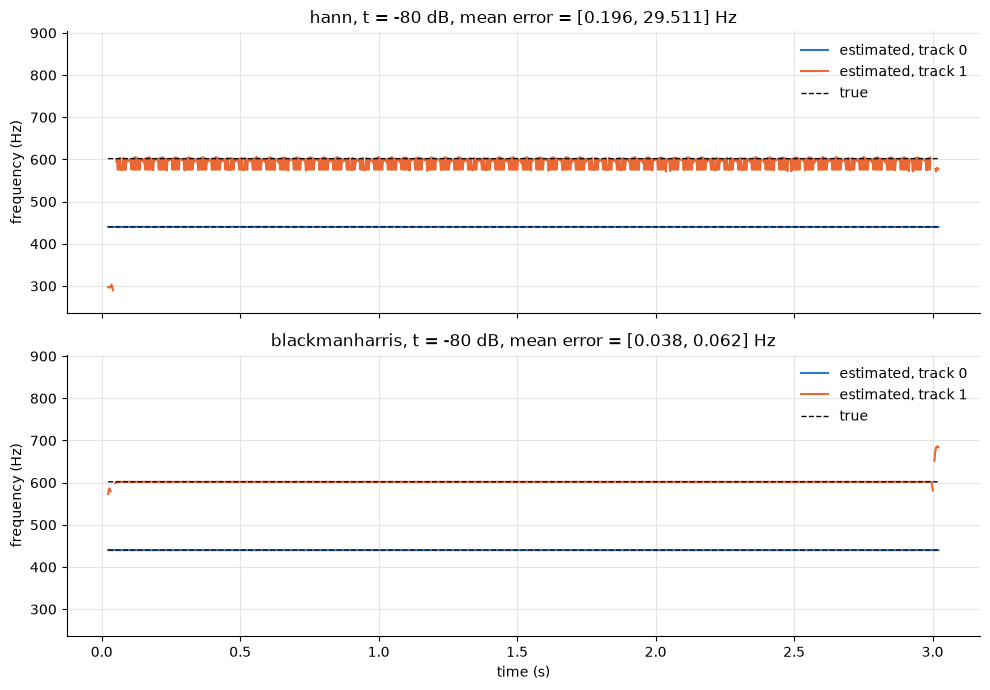

In [16]:
# E5 - 3.1: Call freq_tracker_error() with the baseline parameters and plot true vs estimated tracks.
#            Then choose the best window and threshold, and plot the improved results.

M = 2047
N = 4096
H = 128
input_file = '../sounds/sines-440-602-hRange.wav'
fs, x = UF.wavread(input_file)
tStamps = gen_time_stamps(x.size, M, fs, H)
fTrackTrue = gen_true_freq_tracks_440_602(tStamps)

### Your code here

import matplotlib.pyplot as plt
from unittest.mock import patch

def sine_model_anal_cut(x, fs, w, N, H, t, maxnSines=100, minSineDur=0.01, freqDevOffset=20, freqDevSlope=0.01):
    """sineModelAnal() cutting the tracks to maxnSines in every frame.

    The installed sineModelAnal() only cuts the tracks it returns, not the ones it keeps from frame to frame,
    so the spurious peaks of the first frames fill hidden tracks and the 602 Hz peak ends up in one of them.

    """
    hM1 = (w.size + 1) // 2
    hM2 = w.size // 2
    x = np.concatenate([np.zeros(hM2), x, np.zeros(hM2)])
    w = w / np.sum(w)
    tfreq = np.array([])
    frames = []

    for pin in range(hM1, x.size - hM1, H):
        mX, pX = DFT.dftAnal(x[pin - hM1 : pin + hM2], w, N)
        ploc = UF.peakDetection(mX, t)
        iploc, ipmag, ipphase = UF.peakInterp(mX, pX, ploc)
        tfreq, tmag, tphase = SM.sineTracking(fs * iploc / float(N), ipmag, ipphase, tfreq, freqDevOffset, freqDevSlope)
        tfreq, tmag, tphase = tfreq[:maxnSines], tmag[:maxnSines], tphase[:maxnSines]
        frames.append([np.pad(track, (0, maxnSines - track.size)) for track in (tfreq, tmag, tphase)])

    xtfreq, xtmag, xtphase = np.array(frames).transpose(1, 0, 2)
    return SM.cleaningSineTracks(xtfreq, round(fs * minSineDur / H)), xtmag, xtphase

def track_error(window, t):
    """freq_tracker_error() using sine_model_anal_cut(), only during this call."""
    with patch.object(SM, 'sineModelAnal', sine_model_anal_cut):
        return freq_tracker_error(input_file, fTrackTrue, window, t, H, M)

# 'hann' is the current scipy name of the 'hanning' window of the statement
windows = ['boxcar', 'hann', 'hamming', 'blackman', 'blackmanharris']
thresholds = [-60, -70, -80, -100, -120]

print('mean error of the 602 Hz component (Hz)')
print('        window' + ''.join(f'  t = {t_test:4d}' for t_test in thresholds))
for window in windows:
    print(f'{window:>14s}' + ''.join(f'{track_error(window, t_test)[0][1]:10.3f}' for t_test in thresholds))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)

for ax, (window, t) in zip(axes, [('hann', -80), ('blackmanharris', -80)]):
    meanErr, fTrackEst = track_error(window, t)
    fTrackEst = np.where(fTrackEst > 0, fTrackEst, np.nan)      # 0 means no track in that frame

    ax.plot(tStamps, fTrackEst[:, 0], color='#2a78d6', linewidth=1.5, label='estimated, track 0')
    ax.plot(tStamps, fTrackEst[:, 1], color='#eb6834', linewidth=1.5, label='estimated, track 1')
    ax.plot(tStamps, fTrackTrue, color='#0b0b0b', linestyle='--', linewidth=1)
    ax.plot([], [], color='#0b0b0b', linestyle='--', linewidth=1, label='true')

    ax.set_title(f'{window}, t = {t} dB, mean error = [{meanErr[0]:.3f}, {meanErr[1]:.3f}] Hz')
    ax.set_ylabel('frequency (Hz)')
    ax.grid(True, color='#e5e4e0', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, loc='upper right')

axes[1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

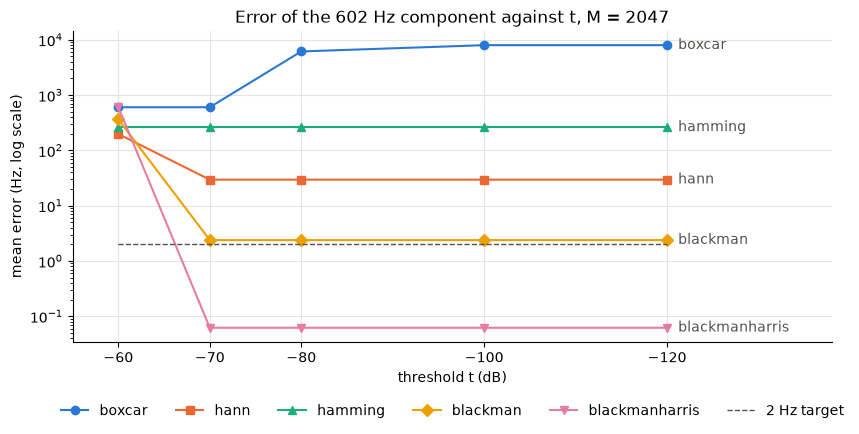

In [17]:
# E5 - 3.1: Error of the 602 Hz component against the threshold, for each window
# (uses windows, thresholds and track_error() from the cell above)

styles = [('#2a78d6', 'o'), ('#eb6834', 's'), ('#1baf7a', '^'), ('#eda100', 'D'), ('#e87ba4', 'v')]      # (color, marker)
errors = np.array([[track_error(window, t_test)[0][1] for t_test in thresholds] for window in windows])

fig, ax = plt.subplots(figsize=(9, 4.5))
for window, window_errors, (color, marker) in zip(windows, errors, styles):
    ax.plot(thresholds, window_errors, color=color, marker=marker, markersize=6, linewidth=1.5, label=window)
    ax.annotate(window, (thresholds[-1], window_errors[-1]), xytext=(8, 0), textcoords='offset points',
                va='center', color='#52514e')

ax.hlines(2, thresholds[0], thresholds[-1], color='#52514e', linestyle='--', linewidth=1, label='2 Hz target')
ax.set_yscale('log')
ax.set_xticks(thresholds)
ax.set_xlim(-55, -138)      # inverted: the threshold gets lower to the right
ax.set_xlabel('threshold t (dB)')
ax.set_ylabel('mean error (Hz, log scale)')
ax.set_title('Error of the 602 Hz component against t, M = 2047')
ax.grid(True, which='major', color='#e5e4e0', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.16))
plt.tight_layout()
plt.show()

**E5 - 3.3: Conceptual questions (answer here)**

1. Look up (or compute) the sidelobe attenuation of the Hanning and Blackman-Harris windows. The weak sinusoid is −60 dB relative to the dominant one. Which window types have sidelobe levels low enough to keep the weak component's main lobe visible? Confirm with your experimental results.
2. Why does lowering the magnitude threshold `t` help track the weak component? What is the risk of setting `t` too low (e.g., `t = -120 dB`)?
3. With `window = 'hanning'` and `t = -80`, the 602 Hz component has error ≈ 30 Hz. From the frequency-track plot, does the tracker follow a sidelobe of the 440 Hz sinusoid instead of the 602 Hz main lobe? How can you tell?


**Respuestas E5 - 3.3**

**1.** La Hann tiene un lóbulo lateral máximo de −31.5 dB y la Blackman-Harris de −92 dB, medidos sobre el espectro de cada ventana. Pero esa cifra no decide por sí sola: lo que importa es el nivel de los lóbulos a 162 Hz del pico de 440 Hz, es decir, a 7.5 bins con `M = 2047`, y compararlo con el nivel real de la componente débil. Esta está a −54 dB y no a −60: `2×10⁻³` es 500 veces menor, no 1000.

| Ventana | Lóbulo lateral máximo (dB) | Lóbulos a 162 Hz (dB) | Margen frente a −54 dB (dB) | Error en 602 Hz (Hz) |
|---|---:|---:|---:|---:|
| `boxcar` | −13.3 | −27.4 | −26.5 | 6146.663 |
| `hamming` | −42.7 | −45.0 | −9.0 | 261.312 |
| `hann` | −31.5 | −62.2 | +8.2 | 29.511 |
| `blackman` | −58.1 | −70.5 | +16.5 | 2.382 |
| `blackmanharris` | −92.0 | −93.1 | +39.1 | 0.062 |

Los resultados confirman esta lectura, con `t = -80`:

- **`boxcar` y `hamming`:** sus lóbulos quedan por encima de la componente débil y la tapan. En la `hamming`, el pico de 602 Hz ni siquiera aparece en una trama central. Solo hay lóbulos laterales en 539, 572 y 628 Hz.
- **`hann`:** a pesar de su mal máximo, sus lóbulos caen rápido y a 162 Hz quedan 8.2 dB por debajo. El pico se ve, pero deformado: 606.5 Hz en una trama central, y solo el 55 % de las tramas queda a menos de 5 Hz de 602.
- **`blackman`:** tiene margen suficiente para ver el pico, pero todavía se desvía (603.6 Hz en una trama central). El 82.5 % de las tramas queda a menos de 5 Hz y el error se queda en 2.382 Hz, justo por encima del objetivo.
- **`blackmanharris`:** es la única con un margen amplio. El pico sale limpio en 602.1 Hz y todas las tramas quedan a menos de 5 Hz.

Por tanto, la Blackman-Harris es la única que mantiene visible el lóbulo principal de la componente débil con el error pedido. Su coste es un lóbulo principal más ancho (172 Hz frente a 86 Hz de la Hann), pero no molesta aquí: su mitad, 86 Hz, es menor que los 162 Hz que separan las componentes.

**2.** Bajar `t` ayuda porque `peakDetection()` descarta los picos que quedan por debajo del umbral, y `t` es un nivel absoluto, no relativo al pico fuerte. El pico de 602 Hz está a −60.4 dB (los −54 dB son respecto al de 440 Hz, que está a −6.5 dB). Por eso, con `blackmanharris` y `t = -60` se queda justo fuera y la pista sale vacía (error de 602 Hz), mientras que con `t = -70` ya se detecta (error de 0.062 Hz).

El riesgo de bajarlo demasiado es llevarse por delante lóbulos laterales y ruido, que pasan a detectarse como si fueran sinusoides y pueden crear pistas falsas. Con `blackmanharris` y `t = -110`, por ejemplo, aparecen picos falsos de −98 a −109 dB entre 172 y 300 Hz. Aquí `t = -120` no empeora el error, porque `maxnSines = 2` y los picos se asignan por magnitud, así que 602 Hz gana a esos picos. Tampoco lo mejora: el error sigue en 0.062 Hz desde `t = -70`. Lo razonable es poner `t` un poco por debajo de la componente más débil que se quiere seguir, sin bajarlo más.

**3.** No. Con `window = 'hann'` y `t = -80`, la pista sigue la sinusoide de 602 Hz, pero deformada por la interferencia con el lóbulo lateral de 440 Hz. A primera vista parece lo contrario, porque hay un lóbulo en `440 + 7.46·fs/M ≈ 600.7` Hz, casi encima de 602 Hz. Pero esa coincidencia no basta, y dos pruebas lo descartan:

- **Sin la componente débil no hay pista:** con un 440 Hz puro y los mismos parámetros, la pista 1 queda vacía en todas las tramas centrales. Con `N = 2048` casi no hay zero-padding, así que los lóbulos ni siquiera aparecen como picos. Además, ese lóbulo está a −62.2 dB, 8.2 dB por debajo de la componente débil.
- **La pista sigue a la componente débil cuando esta se mueve:** con la sinusoide débil en 585, 595, 610, 620 y 640 Hz, la mediana de la pista pasa a 578.7, 592.9, 606.2, 618.8 y 639.4 Hz. Un lóbulo de 440 Hz se quedaría fijo en 600.7 Hz.

En la gráfica se nota porque la pista no es una línea estable, sino que oscila entre unos 575 y 605 Hz con un patrón periódico de unos 0.05 s. El lóbulo se suma al pico débil y lo desplaza según la fase relativa entre las dos sinusoides, que cambia en cada trama. Esa oscilación tiene componentes en la diferencia de frecuencias, 162 Hz, y en su alias a la tasa de tramas: `|fs/H − 2·162| ≈ 20.5` Hz, un periodo de 0.049 s.

El error de unos 30 Hz exagera el problema: la mediana del error es solo 3.8 Hz. Alrededor del 3 % de las tramas no tienen pista y cada una cuenta como 602 Hz de error, lo que aporta unos 18.7 Hz de los 29.5 Hz.

440 Hz alone: 0 central frames with track 1
file: 3.1% empty central frames, median error 3.8 Hz


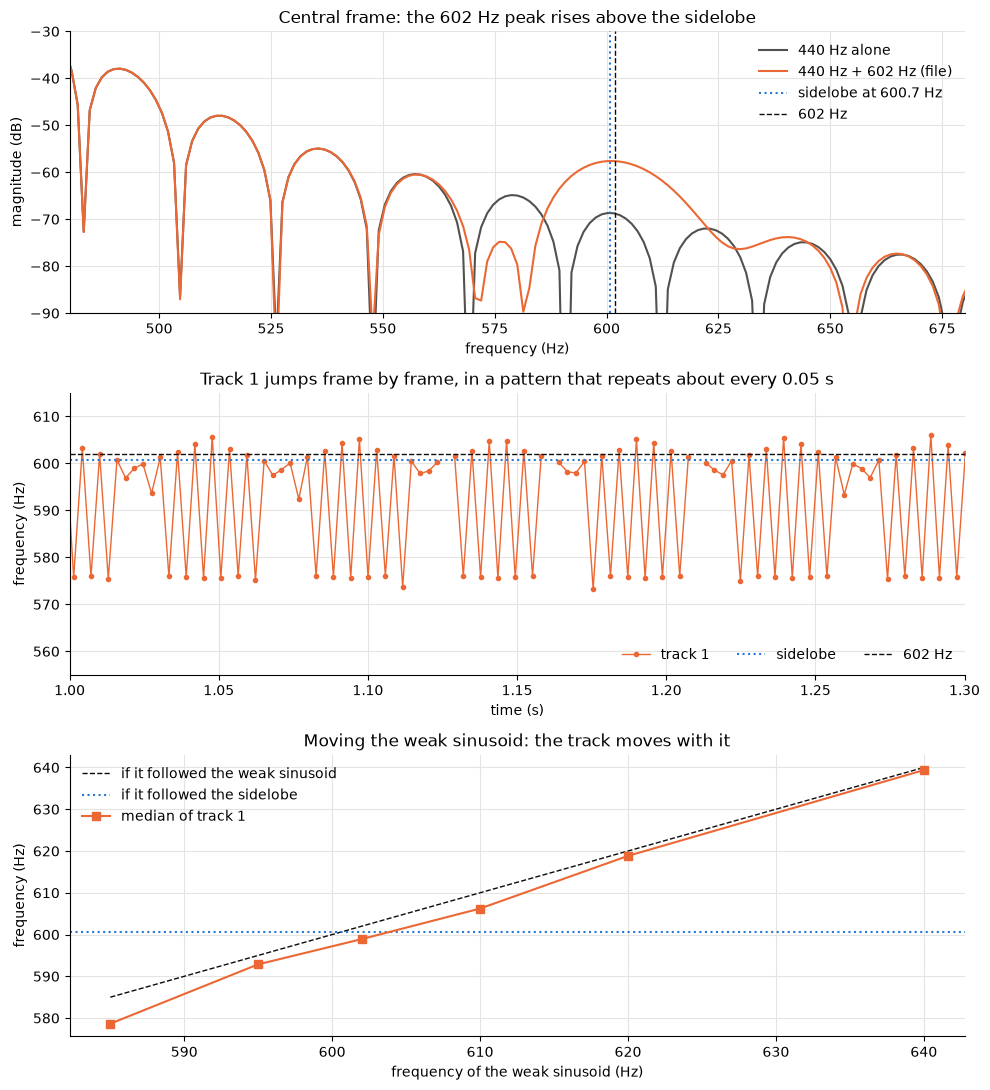

In [18]:
# E5 - 3.3 (question 3): Does the Hann track follow a sidelobe of 440 Hz or the 602 Hz sinusoid?
# (uses x, fs, M, H, tStamps and sine_model_anal_cut() from the E5 - 3.1 cell)

window = 'hann'
t = -80
tailF = 20                                  # frames left out, as in freq_tracker_error()
sidelobe = 440 + 7.46 * fs / M              # Hann sidelobe closest to 602 Hz (600.7 Hz)
A = np.max(np.abs(x)) / 1.002               # amplitude of the 440 Hz sinusoid
n = np.arange(x.size)
pure = A * np.sin(2 * np.pi * 440 * n / fs)

def weak_track(signal):
    """Track 1 with the parameters of freq_tracker_error(), 0 means no track in that frame."""
    fTrackEst, mTrackEst, pTrackEst = sine_model_anal_cut(signal, fs, get_window(window, M), 2048, H, t, 2, 0.0, 30, 0.001)
    return fTrackEst[:, 1]

fig, axes = plt.subplots(3, 1, figsize=(10, 11))

# spectrum of a central frame, with zero padding to see the sidelobes
ax = axes[0]
Nz = 2**15
w = get_window(window, M)
w = w / np.sum(w)
center = x.size // 2
freqs = fs * np.arange(Nz // 2 + 1) / Nz
for signal, color, label in [(pure, '#52514e', '440 Hz alone'), (x, '#eb6834', '440 Hz + 602 Hz (file)')]:
    mX, pX = DFT.dftAnal(signal[center - (M + 1) // 2 : center + M // 2], w, Nz)
    ax.plot(freqs, mX, color=color, linewidth=1.5, label=label)
ax.axvline(sidelobe, color='#2a78d6', linestyle=':', linewidth=1.5, label=f'sidelobe at {sidelobe:.1f} Hz')
ax.axvline(602, color='#0b0b0b', linestyle='--', linewidth=1, label='602 Hz')
ax.set_xlim(480, 680)
ax.set_ylim(-90, -30)
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('magnitude (dB)')
ax.set_title('Central frame: the 602 Hz peak rises above the sidelobe')

# track over time, zoomed in
ax = axes[1]
track = weak_track(x)
central = track[tailF:-tailF]
print(f'440 Hz alone: {np.count_nonzero(weak_track(pure)[tailF:-tailF])} central frames with track 1')
print(f'file: {np.mean(central == 0):.1%} empty central frames, median error {np.median(np.abs(central - 602)):.1f} Hz')
ax.plot(tStamps, np.where(track > 0, track, np.nan), color='#eb6834', marker='o', markersize=3, linewidth=1, label='track 1')
ax.axhline(sidelobe, color='#2a78d6', linestyle=':', linewidth=1.5, label='sidelobe')
ax.axhline(602, color='#0b0b0b', linestyle='--', linewidth=1, label='602 Hz')
ax.set_xlim(1.0, 1.3)
ax.set_ylim(555, 615)
ax.set_xlabel('time (s)')
ax.set_ylabel('frequency (Hz)')
ax.set_title('Track 1 jumps frame by frame, in a pattern that repeats about every 0.05 s')
ax.legend(frameon=False, ncol=3, loc='lower right')

# moving the weak sinusoid
ax = axes[2]
fWeak = [585, 595, 602, 610, 620, 640]
medians = []
for f_test in fWeak:
    track = weak_track(pure + 2e-3 * A * np.sin(2 * np.pi * f_test * n / fs))[tailF:-tailF]
    medians.append(np.median(track[track > 0]))
ax.plot(fWeak, fWeak, color='#0b0b0b', linestyle='--', linewidth=1, label='if it followed the weak sinusoid')
ax.axhline(sidelobe, color='#2a78d6', linestyle=':', linewidth=1.5, label='if it followed the sidelobe')
ax.plot(fWeak, medians, color='#eb6834', marker='s', markersize=6, linewidth=1.5, label='median of track 1')
ax.set_xlabel('frequency of the weak sinusoid (Hz)')
ax.set_ylabel('frequency (Hz)')
ax.set_title('Moving the weak sinusoid: the track moves with it')

axes[0].legend(frameon=False, loc='upper right')
axes[2].legend(frameon=False, loc='upper left')
for ax in axes:
    ax.grid(True, color='#e5e4e0', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

## Part 4 – Sinusoidal modelling of a multicomponent signal

Perform the best possible sinusoidal analysis of `multiSines.wav` by exploring the `sineModelAnal()` parameters. The goal is a resynthesised sound that is perceptually indistinguishable from the input.

`multiSines.wav` combines several challenging features simultaneously:
- Sharp amplitude attacks
- Closely spaced frequency components across a wide amplitude range
- Time-varying chirp tracks that cross over in frequency

Listen to the sound and examine its spectrogram (using `models_GUI.py` or Sonic Visualizer) before choosing parameters.

**Parameters to set:** `window`, `M`, `N`, `t`, `minSineDur`, `maxnSines`, `freqDevOffset`, `freqDevSlope`.

The synthesis parameters `Ns = 512` and `H = 128` are fixed — do not modify them.

> This is an open-ended exploration. Start with a reasonable set of parameters, listen to the output, examine the frequency tracks, and iterate.


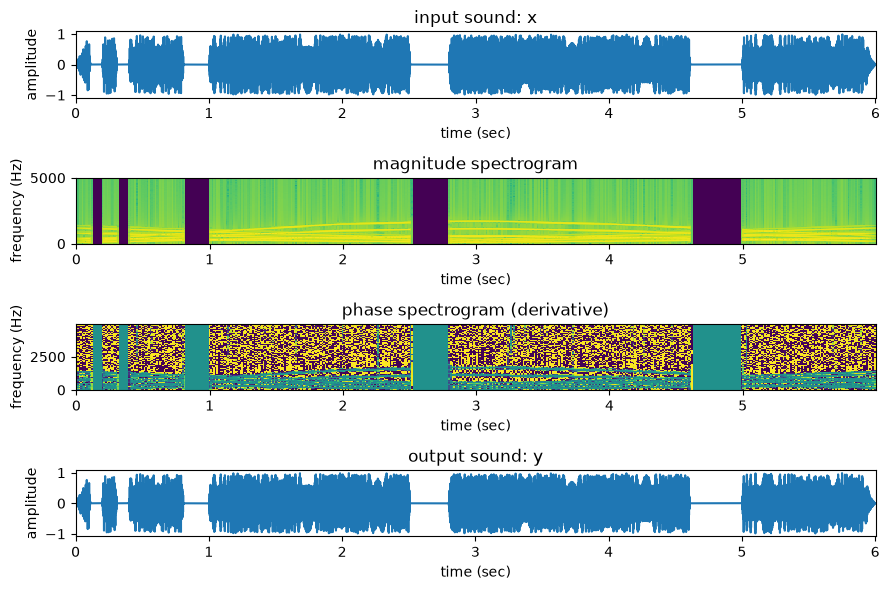

In [19]:
# E5 - 4.1: Listen to multiSines.wav and plot it with the STFT function of models_GUI (default GUI parameters)

import sys
sys.path.append('../interface-models')
import stft_function

input_file = '../sounds/multiSines.wav'
fs, x = UF.wavread(input_file)

ipd.display(ipd.Audio(data=x, rate=fs))
stft_function.main(input_file, window='hamming', M=1024, N=1024, H=512)

In [ ]:
# E5 - 4.1: 
# Set the analysis parameters of sineModelAnal() to perform the best analysis of multiSines.wav

import IPython.display as ipd

input_file = '../sounds/multiSines.wav'

### set the analysis parameters

window = 'blackmanharris'
M = 3001
N = 4096
t = -50
minSineDur = 0.02
maxnSines = 10
freqDevOffset = 20
freqDevSlope = 0.01


# no need to modify the code after here
Ns = 512                                      # size of fft used in synthesis
H = 128                                       # hop size (has to be 1/4 of Ns)

fs, x = UF.wavread(input_file)                # read input sound
w = get_window(window, M)                     # compute analysis window

# analyze the sound with the sinusoidal model
tfreq, tmag, tphase = SM.sineModelAnal(x, fs, w, N, H, t, maxnSines, minSineDur, freqDevOffset, freqDevSlope)

# synthesize the output sound from the sinusoidal representation
y = SM.sineModelSynth(tfreq, tmag, tphase, Ns, H, fs)

# create figure to show plots
plt.figure(figsize=(15, 9))

# frequency range to plot
maxplotfreq = 5000.0

# plot the input sound
plt.subplot(3,1,1)
plt.plot(np.arange(x.size)/float(fs), x)
plt.axis([0, x.size/float(fs), min(x), max(x)])
plt.ylabel('amplitude')
plt.xlabel('time (sec)')
plt.title('input sound: x')

# plot the sinusoidal frequencies
plt.subplot(3,1,2)
if (tfreq.shape[1] > 0):
    numFrames = tfreq.shape[0]
    frmTime = H*np.arange(numFrames)/float(fs)
    tfreq[tfreq<=0] = np.nan
    plt.plot(frmTime, tfreq)
    plt.axis([0, x.size/float(fs), 0, maxplotfreq])
    plt.title('frequencies of sinusoidal tracks')

# plot the output sound
plt.subplot(3,1,3)
plt.plot(np.arange(y.size)/float(fs), y)
plt.axis([0, y.size/float(fs), min(y), max(y)])
plt.ylabel('amplitude')
plt.xlabel('time (sec)')
plt.title('output sound: y')

ipd.display(ipd.Audio(data=x, rate=fs))
ipd.display(ipd.Audio(data=y, rate=fs))

In [ ]:
# E5 - 4.1: barrido de M, N con blackmanharris (resto de parámetros fijos)
import csv, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import get_window
from smstools.models import utilFunctions as UF, sineModel as SM, stft as STFT

input_file = '../sounds/multiSines.wav'
fig_dir, snd_dir = 'figures/E5_sweep', 'output_sounds/E5_sweep'
os.makedirs(fig_dir, exist_ok=True); os.makedirs(snd_dir, exist_ok=True)

# parámetros fijos
window = 'blackmanharris'
t = -70; maxnSines = 20; minSineDur = 0.02; freqDevOffset = 20; freqDevSlope = 0.01
Ns = 512; H = 128

# barrido
Ms = [2647, 4001, 6615, 8821, 11673, 16539]
def nextpow2(n): return int(2**np.ceil(np.log2(n)))
combos = [(M, nextpow2(M)*k) for M in Ms for k in (1, 2)]

segs = [(0.00, 0.11), (0.20, 0.31), (0.40, 0.81), (1.00, 2.51), (2.80, 4.61), (5.00, 6.00)]
onsets = [0.20, 0.40, 1.00, 2.80, 5.00]
pairs = {'24Hz (539/563 @3.2s)': [(3.2, 539), (3.2, 563)],
         '60Hz (179/239 @2.2s)': [(2.2, 179), (2.2, 239)],
         '60Hz (120/180 @3.2s)': [(3.2, 120), (3.2, 180)]}

fs, x = UF.wavread(input_file)

def hay_pista(tfreq, tc, f, tol=3):
    i = int(round(tc*fs/H)); fila = tfreq[i]
    return bool(np.any(np.abs(fila - f) < tol))

def arranques(tfreq):
    act = tfreq > 0
    return int(act[0].sum() + np.sum(~act[:-1] & act[1:]))

def snr_dB(a, b):
    return 10*np.log10(np.sum(a**2) / np.sum((a-b)**2))

def preeco_dB(x, y, t_on, d=0.02):
    n, k = int(t_on*fs), int(d*fs)
    return 10*np.log10(np.sum(y[n-k:n]**2) / np.sum(x[n:n+k]**2) + 1e-20)

# espectrograma de fondo para las figuras de pistas
mXb, _ = STFT.stftAnal(x, get_window('blackmanharris', 4001), 8192, 256)
fb = fs*np.arange(mXb.shape[1])/8192; nb = int(2000*8192/fs)
tb = 256*np.arange(mXb.shape[0])/fs

rows, results = [], {}
for M, N in combos:
    w = get_window(window, M)
    tfreq, tmag, tphase = SM.sineModelAnal(x, fs, w, N, H, t, maxnSines, minSineDur, freqDevOffset, freqDevSlope)
    y = SM.sineModelSynth(tfreq, tmag, tphase, Ns, H, fs)
    L = min(len(x), len(y)); xs, ys = x[:L], y[:L]
    UF.wavwrite(ys, fs, f'{snd_dir}/y_M{M}_N{N}.wav')
    UF.wavwrite(xs - ys, fs, f'{snd_dir}/res_M{M}_N{N}.wav')
    results[(M, N)] = (tfreq.copy(), ys)
    row = {'M': M, 'N': N, 'dur (s)': round(M/fs, 3), 'SNR global': round(snr_dB(xs, ys), 1)}
    for k, (a, b) in enumerate(segs, 1):
        i0, i1 = int(a*fs), min(int(b*fs), L)
        row[f'SNR seg{k}'] = round(snr_dB(xs[i0:i1], ys[i0:i1]), 1)
    row['pre-eco medio'] = round(np.mean([preeco_dB(xs, ys, o) for o in onsets]), 1)
    for name, pts in pairs.items():
        row[name] = all(hay_pista(tfreq, tc, f) for tc, f in pts)
    row['arranques'] = arranques(tfreq)
    rows.append(row)
    print(M, N, 'ok', flush=True)

cols = list(rows[0].keys())
print(' | '.join(cols))
for r in rows: print(' | '.join(str(r[c]) for c in cols))
with open(f'{fig_dir}/tabla_barrido.csv', 'w', newline='') as fh:
    wr = csv.DictWriter(fh, fieldnames=cols); wr.writeheader(); wr.writerows(rows)

# figura de pistas sobre espectrograma (una por combinación, en rejilla 6x2)
fig, axes = plt.subplots(len(Ms), 2, figsize=(22, 4*len(Ms)), sharex=True, sharey=True)
for ax, (M, N) in zip(axes.flat, combos):
    tfreq = results[(M, N)][0].copy(); tfreq[tfreq <= 0] = np.nan
    ax.pcolormesh(tb, fb[:nb], mXb[:, :nb].T, shading='auto', cmap='Greys', vmin=mXb.max()-90, vmax=mXb.max())
    ax.plot(H*np.arange(tfreq.shape[0])/fs, tfreq, lw=0.9)
    ax.set_ylim(0, 2000); ax.set_title(f'M={M} ({M/fs:.3f} s), N={N}')
for ax in axes[-1]: ax.set_xlabel('tiempo (s)')
for ax in axes[:, 0]: ax.set_ylabel('Hz')
fig.tight_layout(); fig.savefig(f'{fig_dir}/pistas_barrido.png', dpi=110); plt.show()

# zoom de ataques: x vs y en cada onset, para N mínimo de cada M
fig, axes = plt.subplots(len(Ms), len(onsets), figsize=(22, 2.6*len(Ms)), sharey=True)
for r, M in enumerate(Ms):
    N = nextpow2(M); ys = results[(M, N)][1]
    for c, o in enumerate(onsets):
        i0, i1 = int((o-0.03)*fs), int((o+0.03)*fs); tt = np.arange(i0, i1)/fs
        ax = axes[r, c]; ax.plot(tt, x[i0:i1], color='0.6', lw=1, label='x'); ax.plot(tt, ys[i0:i1], color='#d62a2a', lw=0.8, label='y')
        ax.axvline(o, color='k', ls=':', lw=0.8)
        if r == 0: ax.set_title(f'ataque {o} s')
        if c == 0: ax.set_ylabel(f'M={M}')
axes[0, 0].legend(loc='upper left')
fig.tight_layout(); fig.savefig(f'{fig_dir}/ataques_barrido.png', dpi=110); plt.show()

**E5 - 4.3: Conceptual questions (answer here)**

1. Describe the main challenges you identified in `multiSines.wav` from the spectrogram. Which feature was hardest to handle — the sharp attacks, the wide amplitude range, or the crossing chirp tracks? Explain why.
2. Report the final parameter values you chose (`window`, `M`, `t`, `maxnSines`, `minSineDur`, `freqDevOffset`, `freqDevSlope`). For each parameter, explain *why* you chose that value, linking it to a specific property of the signal.
3. Listen carefully to the resynthesised output. Are there any audible artefacts or missing components? If so, describe them and explain which aspect of the sinusoidal model is responsible.
4. Is there a single parameter set that handles all the challenging features of this signal simultaneously, or did you have to make tradeoffs? Describe any tradeoffs you encountered.


**Respuestas E5 - 4.3**

**1.** El sonido tiene ataques bruscos tras silencios, componentes muy cercanas (de 24 a 60 Hz) con amplitudes muy distintas (de −19 a −45 dB), y chirps que se cruzan. Lo más difícil fue combinar las componentes cercanas con los ataques: las primeras piden una ventana larga y los segundos una corta.

![espectrograma](figures/E5_4_1_multiSines_spectrogram.png)

**2.**
- `window = 'blackmanharris'`: lóbulos laterales muy bajos, para que no tapen las componentes débiles.
- `M = 3001`: la ventana más corta que separa los pares de 60 Hz.
- `N = 4096`: potencia de 2 ≥ M.
- `t = −50`: por debajo de la componente más débil (−45 dB), sin captar ruido.
- `minSineDur = 0.02`: quita pistas espurias muy cortas.
- `maxnSines = 10`: como mucho hay 9 componentes a la vez.
- `freqDevOffset = 20`, `freqDevSlope = 0.01`: valores por defecto; los chirps cambian lento entre frames y no influyen.

![pistas](figures/E5_sweep_small/pistas_barrido.png)

**3.** Suena casi igual que el original. Los ataques quedan algo suavizados y el par de 24 Hz (539/563 Hz) no se separa, porque la ventana no es lo bastante larga.

![artefactos](figures/E5_final/artefactos.png)

**4.** Sí, hay un compromiso en M. Una ventana larga separa las frecuencias cercanas pero emborrona los ataques; una corta hace lo contrario. M = 3001 es el punto intermedio.